# Chart CNN baseline — 5-minute US equities

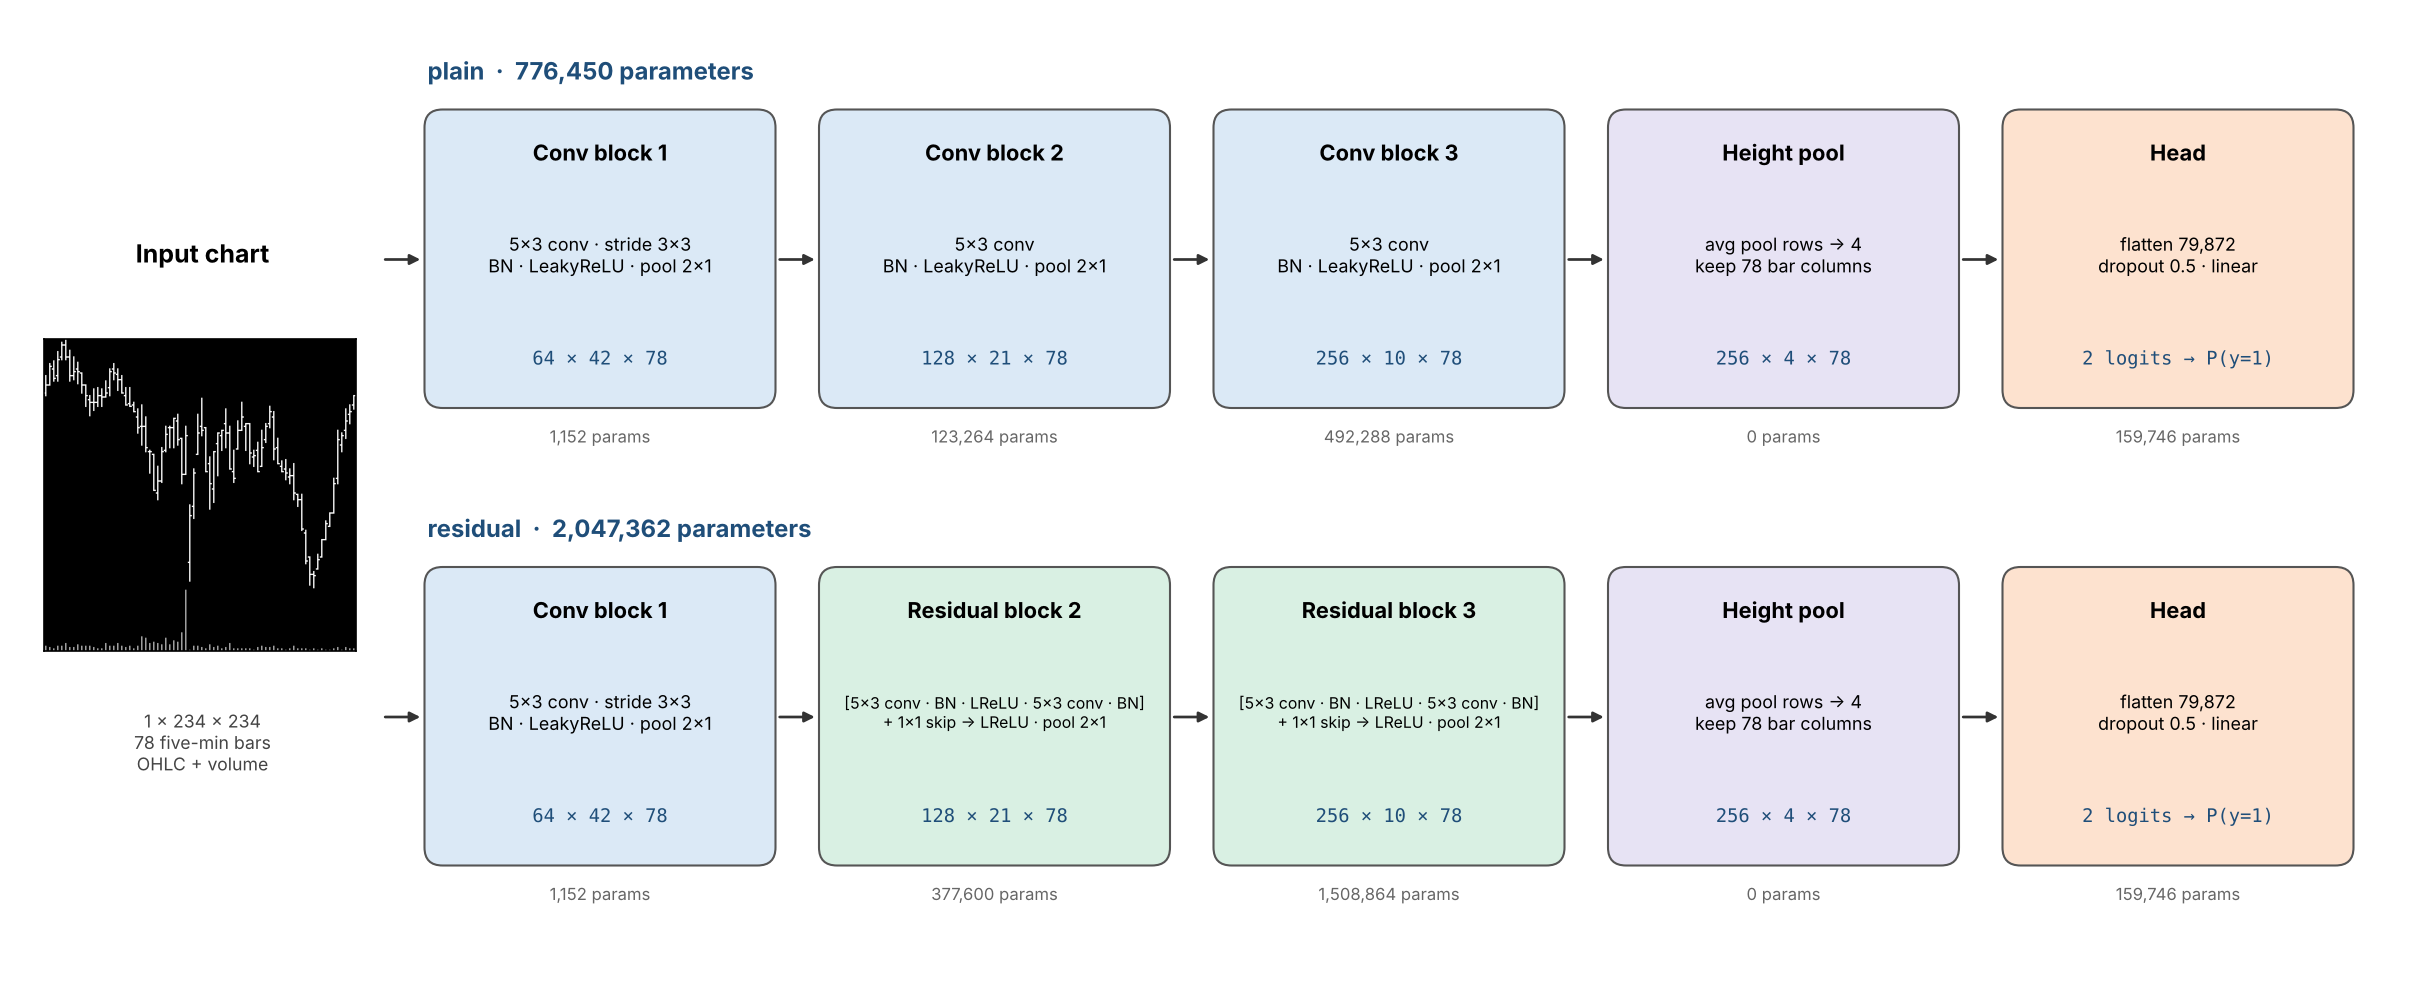

- **Input**: one trading day (78 five-minute bars) drawn as a 234×234 OHLC + volume chart.
- **Models**: `plain` (Jiang–Kelly–Xiu style, top) and `residual` (blocks 2–3 become ResNet basic blocks with a skip connection, bottom), plus `series1d`: a 1D CNN fed the same windows as raw OHLCV numbers (no image), to test whether the picture itself helps.
- **Targets**: `vol_h1` (is the next bar's move larger than usual?), `xsdir_h12` (does the stock beat the cross-sectional median over the next hour?), and absolute direction `dir_h1` / `dir_h12` (is the return over the next bar / hour strictly positive? zero returns are dropped).
- **Price adjustment**: every window is adjusted to its own last bar (point in time), so no later split or dividend reaches the input.
- **Benchmarks**: training prior, simple rules, gradient-boosted trees on hand-made features.
- **Code**: all logic lives in `chartcnn/` next to this notebook; cells only configure, run and plot.
- **Drive layout**: `Demo/cnn78u_colab_bundle.zip` (data) and `Demo/CNN-Relevant/` (this notebook, `chartcnn/`, `runs/`).

## 1. Setup

In [ ]:
import os, sys, shutil, tempfile
from pathlib import Path

LOCAL_TEST = os.environ.get("CNN78U_LOCAL_NOTEBOOK_TEST") == "1"     # repository QA only
if LOCAL_TEST:
    DEMO = Path(os.environ["CNN78U_LOCAL_DEMO"])
else:
    from google.colab import drive
    drive.mount("/content/drive")
    DEMO = Path("/content/drive/MyDrive/Colab Notebooks/EC/Project/Demo")
DRIVE = DEMO / "CNN-Relevant"                     # this notebook, chartcnn/ and run outputs
sys.path.insert(0, str(DRIVE))                    # makes CNN-Relevant/chartcnn importable

import numpy as np, pandas as pd, torch
from IPython.display import display
import chartcnn
from chartcnn import analysis, frame_corr, plots
from chartcnn.training import run_experiment, evaluate_test
from chartcnn.utils import stage_bundle, save_json

LOCAL = Path(tempfile.mkdtemp(prefix="chartcnn_", dir=None if LOCAL_TEST else "/content"))
PREPARED = stage_bundle(DEMO, LOCAL / "bundle")  # unzip data to fast local disk
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("data:", PREPARED, "| device:", DEVICE)
from IPython.display import Image
display(Image(filename=str(DRIVE / "assets" / "network_flow.png"), width=1000))   # network flow (also at the top)

## 2. Configuration
Change settings here only. Set `RESUME=True` with the old `RUN_ID` to continue after a disconnect.

In [ ]:
from datetime import datetime, timezone
SMOKE = LOCAL_TEST                                # tiny code check; never a result
assert DEVICE.type == "cuda" or SMOKE, "Select a GPU runtime"

SETTINGS = dict(
    learning_rate=1e-5, weight_decay=0.0,         # Adam, as in Jiang-Kelly-Xiu
    batch_size=4 if SMOKE else 128, eval_batch_size=8 if SMOKE else 512,
    epochs=1 if SMOKE else 12, patience=2, min_delta=1e-5,   # early stop on validation log loss
    stride=6,                                     # one sample per stock every 30 minutes
    channels=[64, 128, 256], head_height=4, dropout=0.5,
    num_workers=0 if SMOKE else min(8, os.cpu_count() or 2),
    seed=69,
)
EXPERIMENTS = [
    dict(name="vol_h1", target="vol", horizon=1),                    # sanity check: signal is known to exist
    dict(name="dir_h1", target="dir", horizon=1),                    # next bar strictly up vs down (zeros dropped)
    dict(name="xsdir_h12", target="xs_dir", horizon=12, stride=12),  # 1-hour relative direction; stride =
    dict(name="dir_h12", target="dir", horizon=12, stride=12),       # 1-hour absolute direction; horizon so
]                                                                    # labels do not overlap
ARCHS = ["plain", "residual", "series1d"]         # image CNN, image ResNet, 1D CNN on raw OHLCV (no image)
RESUME, RUN_ID = False, "local_smoke" if LOCAL_TEST else datetime.now(timezone.utc).strftime("run_%Y%m%d_%H%M%S")
RUN_DRIVE, RUN_LOCAL = DRIVE / "runs" / RUN_ID, LOCAL / "run"
if RESUME:
    shutil.copytree(RUN_DRIVE, RUN_LOCAL)
else:
    assert LOCAL_TEST or not RUN_DRIVE.exists(), "RUN_ID exists: pick a new one or set RESUME=True"
    RUN_DRIVE.mkdir(parents=True, exist_ok=True); RUN_LOCAL.mkdir()
save_json(RUN_LOCAL / "settings.json", dict(settings=SETTINGS, experiments=EXPERIMENTS, archs=ARCHS), RUN_DRIVE)
print("results ->", RUN_DRIVE)

## 3. Models
Layer-by-layer output shapes and parameter counts for every architecture. Output layers start at zero, so every initial prediction is exactly 0.5.

In [ ]:
store = chartcnn.Store(PREPARED)
sample, _ = chartcnn.build_split(store, "train", "vol", 1, SETTINGS["stride"])
for arch in ARCHS:
    data = chartcnn.make_dataset(PREPARED, sample.head(4), arch)
    x = torch.stack([data[i][0] for i in range(4)])
    model = chartcnn.build_model(dict(SETTINGS, arch=arch))
    table, total, trainable = chartcnn.parameter_table(model)
    print(f"{arch}: {total:,} parameters ({trainable:,} trainable)")
    display(table)
    print("initial P(y=1):", model.eval()(x).softmax(1)[:, 1].tolist(), "\n")
del model

## 4. Frame correlation (data)
A *frame* is one chart image. With stride 6, frame *t* and frame *t+6* share 72 of 78 bars, and all stocks at one timestamp share the market's move. Both make the effective sample size much smaller than the image count.

In [ ]:
LAGS = frame_corr.DEFAULT_LAGS
anchors = frame_corr.sample_anchors(store, "validation", 64 if SMOKE else 400, LAGS)
similarity = frame_corr.image_similarity(PREPARED, anchors, LAGS)

label_acf, ess = {}, []
for exp in EXPERIMENTS:
    acf, frame, _ = frame_corr.label_autocorrelation(store, exp["target"], exp["horizon"], "train",
                                                     list(range(1, 79)) + [156])
    icc, m = frame_corr.cross_sectional_share(frame)
    a = acf.set_index("lag").label_autocorr
    ess += [dict(experiment=exp["name"], icc=round(icc, 4),
                 **frame_corr.effective_sample_size(len(frame), s, a, icc, m)) for s in (1, 6, 12, 78)]
    label_acf[exp["name"]] = acf

display(similarity.round(3))
display(pd.DataFrame(ess))
plots.plot_frame_corr(similarity, label_acf, SETTINGS["stride"], RUN_LOCAL / "frame_corr_data.png")

## 5. Train and validate
Per experiment: build labels → fit baselines → train the CNN → compare on validation. Watch `val AUC`, the log-loss gain vs prior (must be > 0) and `prob std` (≈ 0 means collapse).

In [ ]:
RESULTS = {}
for exp in EXPERIMENTS:
    for arch in ARCHS:
        key = f"{exp['name']}_{arch}"
        print("\n" + "=" * 25, key, "=" * 25)
        RESULTS[key] = run_experiment(PREPARED, exp, dict(SETTINGS, arch=arch), DEVICE,
                                      RUN_LOCAL / key, RUN_DRIVE / key, smoke=SMOKE)
        display(RESULTS[key]["table"].round(4))
        print("top-minus-bottom decile:", RESULTS[key]["long_short"])

# One row per (experiment, architecture): the CNN next to its strongest baseline.
summary = pd.DataFrame([dict(run=k, cnn_auc=r["table"].loc["CNN", "roc_auc"],
                             hgb_auc=r["table"].loc["hgb_hand_features", "roc_auc"],
                             cnn_log_loss_gain_pct=r["table"].loc["CNN", "log_loss_gain_vs_prior_pct"],
                             best_epoch=int(r["history"].loc[r["history"].val_log_loss.idxmin(), "epoch"]))
                        for k, r in RESULTS.items()])
display(summary.round(4)); summary.to_csv(RUN_LOCAL / "summary.csv", index=False)

## 6. Results

In [ ]:
for name, result in RESULTS.items():
    plots.plot_experiment(name, result, RUN_LOCAL / f"{name}_curves.png")

## 7. Analysis
Plain vs residual and CNN vs baselines, per target. Intervals come from resampling whole validation days (frames within a day are strongly correlated, see section 4). The takeaways below are generated from the numbers.

In [ ]:
from IPython.display import Markdown
PARAMS = {a: sum(p.numel() for p in chartcnn.build_model(dict(SETTINGS, arch=a)).parameters()) for a in ARCHS}
ANALYSIS, BOOTS = analysis.summary_table(RESULTS, PARAMS, n_boot=50 if SMOKE else 300)
display(ANALYSIS.round(4)); ANALYSIS.to_csv(RUN_LOCAL / "analysis.csv")
analysis.plot_analysis(RESULTS, ANALYSIS, RUN_LOCAL / "analysis.png")
TAKEAWAYS = analysis.takeaways(RESULTS, ANALYSIS, BOOTS)
(RUN_LOCAL / "takeaways.md").write_text(TAKEAWAYS); display(Markdown(TAKEAWAYS))
for name in ("analysis.csv", "analysis.png", "takeaways.md"):
    shutil.copy2(RUN_LOCAL / name, RUN_DRIVE / name)

## 8. Frame correlation (model)
Same anchors as section 4, now seen through each trained CNN: correlation of feature maps (`_embed`) and of predictions (`_prob`) between frame *t* and *t+k*.

In [ ]:
trained = {}
for key in RESULTS:
    if chartcnn.INPUT_KIND[key.rsplit("_", 1)[1]] != "image":
        continue                                  # frame similarity is defined on images
    m = chartcnn.build_model(dict(SETTINGS, arch=key.rsplit("_", 1)[1]))
    m.load_state_dict(torch.load(RUN_LOCAL / key / "best.pt", map_location="cpu", weights_only=False)["model"])
    chartcnn.print_parameter_count(m, key)
    trained[key] = m
similarity = frame_corr.image_similarity(PREPARED, anchors, LAGS, models=trained, device=DEVICE)
display(similarity.round(3))
plots.plot_frame_corr(similarity, label_acf, SETTINGS["stride"], RUN_LOCAL / "frame_corr_model.png")
similarity.to_csv(RUN_LOCAL / "frame_similarity.csv", index=False)

## 9. Held-out test (off by default)
May–June 2023 has been looked at before, so it is no longer a clean holdout. Run once, after the protocol is frozen.

In [ ]:
RUN_TEST = False
for exp in EXPERIMENTS if RUN_TEST else []:
    for arch in ARCHS:
        key = f"{exp['name']}_{arch}"
        r = RESULTS[key]
        out = evaluate_test(PREPARED, exp, dict(SETTINGS, arch=arch), DEVICE, RUN_LOCAL / key,
                            r["median"], r["prior"], RUN_DRIVE / key, smoke=SMOKE)
        print(key); display(pd.Series(out["test"]).round(4)); print("long-short:", out["long_short"])

## 10. Save

In [ ]:
archive = shutil.make_archive(str(LOCAL / "results"), "zip", root_dir=RUN_LOCAL)
shutil.copy2(archive, RUN_DRIVE / "results.zip")
print("saved", RUN_DRIVE / "results.zip", "| RUN_ID:", RUN_ID)